In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df1 = pd.read_csv("D:\\GIT\\Demeter-Anomaly-Detection-Framework\\Result Files\\Z-factor-files\\Qfactor-SW22x22_TW48-all_newz.csv")
df2 = pd.read_csv("D:\\GIT\\Demeter-Anomaly-Detection-Framework\\Result Files\\STSM\\Qfactor-SW22x22_TW48-all_newz-temporal_attention.csv")

In [4]:
df1.head()



,Naming,RST_Median,RST_99.7,Q_all,Q_tr_all,z_va_all,z_tr_all,z_tr_err32_all,z_va_err32_all,z_tr_err68_all,z_va_err68_all,avg_train_all,err_train_all,avg_val_all,err_val_all,mode,tw
0,tw48-30dBG_A,55.0,64.5015,1.603147,2.058188,0.580345,1.483903,0.969415,0.027546,1.883093,1.586655,65.565855,2.005673,60.655406,3.382304,all,48
1,tw48-30dBG_B,55.0,64.5015,1.588039,1.620922,0.931967,1.205064,0.995293,0.274084,1.591042,1.637739,64.001267,2.045376,64.962796,3.285515,all,48
2,tw48-30dBG_C,55.0,64.5015,1.918813,2.231383,1.036936,1.709222,1.219155,0.689689,2.029834,1.936428,67.039413,1.999174,65.378483,3.337975,all,48
3,tw48-30dBG_D,55.0,64.5015,1.568515,2.800605,0.770513,1.951724,1.070447,0.354388,2.719786,1.488363,67.707816,1.954480,62.597034,3.344383,all,48
4,tw48-30dBG_E,55.0,64.5015,2.038967,4.002085,1.268752,3.592936,2.609090,0.670258,4.470986,2.207403,77.594455,1.768752,66.375231,2.951503,all,48


In [5]:
df2.head()

,Naming,RST_Median,RST_99.7,z_va_all,z_tr_all,z_tr_err32_all,z_va_err32_all,z_tr_err68_all,z_va_err68_all,avg_train_all,err_train_all,avg_val_all,err_val_all,mode,tw
0,tw48-30dBG_A-temporal_attention,55.0,64.5,0.916636,1.134934,0.690165,0.095210,1.642272,1.757329,63.326647,2.048016,65.100888,3.330967,all,48
1,tw48-30dBG_B-temporal_attention,55.0,64.5,0.895793,1.580057,0.917118,0.579344,2.387482,1.751411,66.206193,2.001241,64.857522,3.320376,all,48
2,tw48-30dBG_C-temporal_attention,55.0,64.5,0.984521,2.138382,1.410251,0.907643,2.631664,1.979106,69.688249,1.947499,64.980729,3.213712,all,48
3,tw48-30dBG_D-temporal_attention,55.0,64.5,1.031514,2.010139,1.336031,0.882928,2.232361,1.655233,69.135692,1.967230,65.155883,3.356556,all,48
4,tw48-30dBG_E-temporal_attention,55.0,64.5,1.156622,2.684080,1.459097,0.411269,3.574386,1.788518,72.721596,1.872392,67.494994,3.332753,all,48


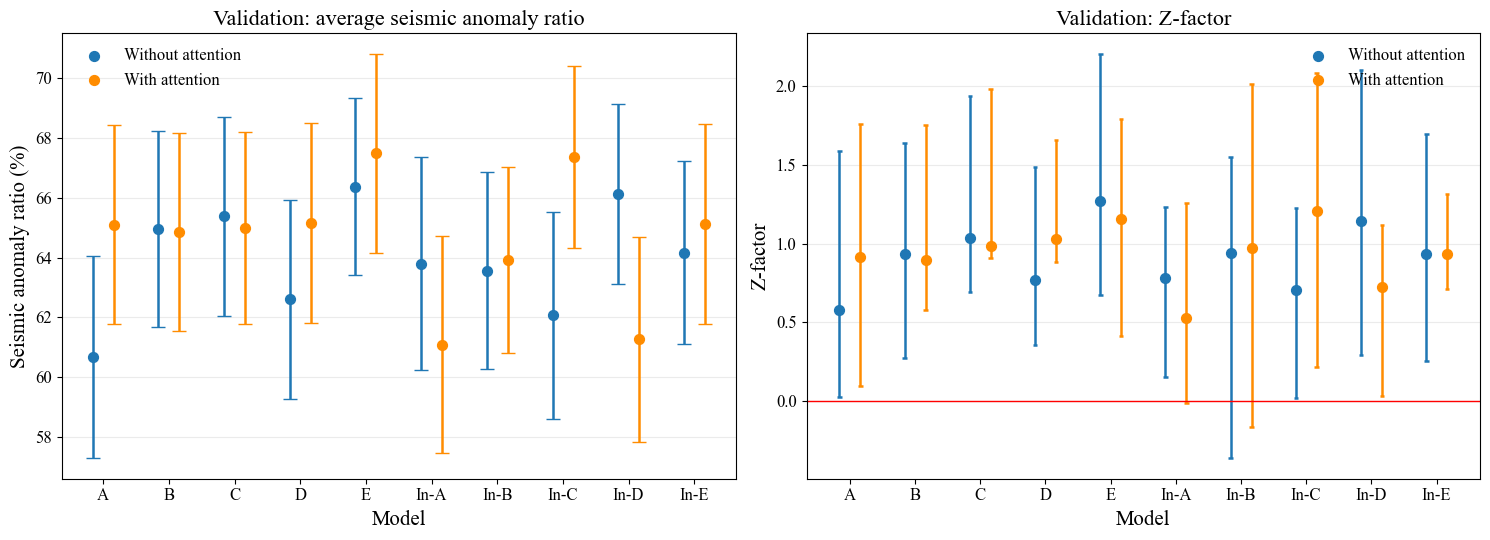

In [8]:
# Run after the preparation section:
# baseline, attention, models, and comparison_dir must already exist.

plt.rcParams["font.family"] = "Times New Roman"

x = np.arange(len(models))
offset = 0.16

categories = [
    (baseline, "Without attention", "tab:blue", -offset),
    (attention, "With attention", "darkorange", offset),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for frame, label, color, shift in categories:
    positions = x + shift

    # ------------------------------------------------------
    # Validation average ratio with original propagated error
    # ------------------------------------------------------
    values = frame["avg_val_all"].to_numpy(float)
    errors = frame["err_val_all"].to_numpy(float)

    valid = np.isfinite(values)
    usable = valid & np.isfinite(errors) & (errors >= 0)

    axes[0].scatter(
        positions[valid], values[valid],
        color=color, s=50, label=label, zorder=3,
    )
    axes[0].errorbar(
        positions[usable], values[usable],
        yerr=errors[usable],
        fmt="none", ecolor=color,
        capsize=5, linewidth=1.8,
    )

    # ------------------------------------------------------
    # Validation Z-factor with 32–68% percentile endpoints
    # ------------------------------------------------------
    z = frame["z_va_all"].to_numpy(float)
    lower = frame["z_va_err32_all"].to_numpy(float)
    upper = frame["z_va_err68_all"].to_numpy(float)

    valid = np.isfinite(z)
    usable = (
        valid & np.isfinite(lower) & np.isfinite(upper)
        & (lower <= upper)
    )

    axes[1].scatter(
        positions[valid], z[valid],
        color=color, s=50, label=label, zorder=3,
    )
    axes[1].vlines(
        positions[usable], lower[usable], upper[usable],
        color=color, linewidth=1.8,
    )

    # Caps at the percentile endpoints
    cap_width = 0.035
    for endpoints in (lower, upper):
        axes[1].hlines(
            endpoints[usable],
            positions[usable] - cap_width,
            positions[usable] + cap_width,
            color=color, linewidth=1.8,
        )

axes[0].set_title("Validation: average seismic anomaly ratio", fontsize=16)
axes[0].set_ylabel("Seismic anomaly ratio (%)", fontsize=15)

axes[1].set_title("Validation: Z-factor", fontsize=16)
axes[1].set_ylabel("Z-factor", fontsize=15)
axes[1].axhline(0, color="red", linewidth=1)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=12)
    ax.set_xlabel("Model", fontsize=15)
    ax.tick_params(axis="y", labelsize=12)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=12, frameon=False)

fig.tight_layout()
fig.savefig(
    comparison_dir / "Validation_ratio_and_Z_with_errors.png",
    dpi=600,
    bbox_inches="tight",
)
plt.show()